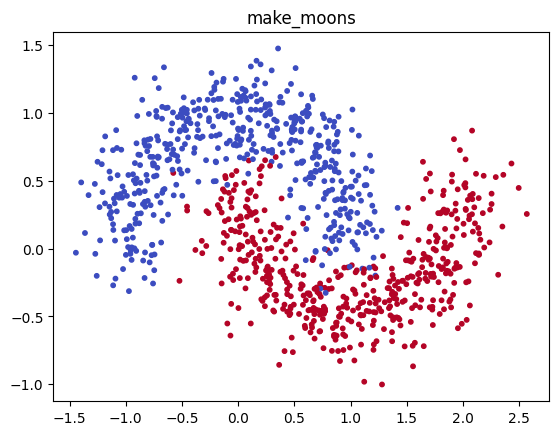

Logistic regression test acc: 0.86


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

X, y = make_moons(n_samples=1000, noise=0.2, random_state=42)
y = y.reshape(-1, 1)                      # (1000,) → (1000, 1)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

plt.scatter(X[:, 0], X[:, 1], c=y.ravel(), cmap="coolwarm", s=10)
plt.title("make_moons"); plt.show()

logreg = LogisticRegression().fit(X_train, y_train.ravel())
print("Logistic regression test acc:", logreg.score(X_test, y_test.ravel()))

In [2]:
def relu(z):
    return np.maximum(0, z)

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def bce(p, y):
    p = np.clip(p, 1e-12, 1 - 1e-12)
    return float(-np.mean(y * np.log(p) + (1 - y) * np.log(1 - p)))

In [3]:
np.random.seed(0)
W1 = np.random.randn(2, 16) * 0.1     # input 2 → hidden 16
b1 = np.zeros((1, 16))
W2 = np.random.randn(16, 1) * 0.1     # hidden 16 → output 1
b2 = np.zeros((1, 1))

In [4]:
def forward(X, W1, b1, W2, b2):
    z1 = X @ W1 + b1      # (n, 16)  hidden layer raw scores
    a1 = relu(z1)         # (n, 16)  bend
    z2 = a1 @ W2 + b2     # (n, 1)   output raw score
    p  = sigmoid(z2)      # (n, 1)   probability
    return z1, a1, z2, p

In [5]:
def backward(X, y, z1, a1, p, W2):
    n = X.shape[0]

    # Output layer
    dz2 = p - y                                  # (n, 1)
    dW2 = a1.T @ dz2 / n                         # (16, 1)
    db2 = dz2.mean(axis=0, keepdims=True)        # (1, 1)

    # Hidden layer (chain rule: error ni venakki pampadam)
    da1 = dz2 @ W2.T                             # (n, 16)
    dz1 = da1 * (z1 > 0)                         # (n, 16)
    dW1 = X.T @ dz1 / n                          # (2, 16)
    db1 = dz1.mean(axis=0, keepdims=True)        # (1, 16)

    return dW1, db1, dW2, db2

In [7]:
z1, a1, z2, p = forward(X_train, W1, b1, W2, b2)
dW1, db1, dW2, db2 = backward(X_train, y_train, z1, a1, p, W2)

assert dW1.shape == W1.shape and dW2.shape == W2.shape
print("Shapes OK ✅")

Shapes OK ✅


In [8]:
eps = 1e-5
i, j = 0, 3                       # W1 lo oka weight pick chesam

W_plus = W1.copy();  W_plus[i, j] += eps
W_minus = W1.copy(); W_minus[i, j] -= eps

loss_plus  = bce(forward(X_train, W_plus,  b1, W2, b2)[3], y_train)
loss_minus = bce(forward(X_train, W_minus, b1, W2, b2)[3], y_train)
numerical = (loss_plus - loss_minus) / (2 * eps)

print("Numerical:", numerical)
print("Backprop: ", dW1[i, j])
print("Difference:", abs(numerical - dW1[i, j]))

Numerical: -0.002813183402894381
Backprop:  -0.002813183396145076
Difference: 6.749305107855985e-12


In [9]:
max_diff = 0
for i in range(W1.shape[0]):
    for j in range(W1.shape[1]):
        Wp = W1.copy(); Wp[i, j] += eps
        Wm = W1.copy(); Wm[i, j] -= eps
        num = (bce(forward(X_train, Wp, b1, W2, b2)[3], y_train)
             - bce(forward(X_train, Wm, b1, W2, b2)[3], y_train)) / (2 * eps)
        max_diff = max(max_diff, abs(num - dW1[i, j]))
print("Max difference across all W1:", max_diff)

Max difference across all W1: 1.0328578270435429e-11


step 0: loss 0.6843
step 500: loss 0.2675
step 1000: loss 0.2538
step 1500: loss 0.2501


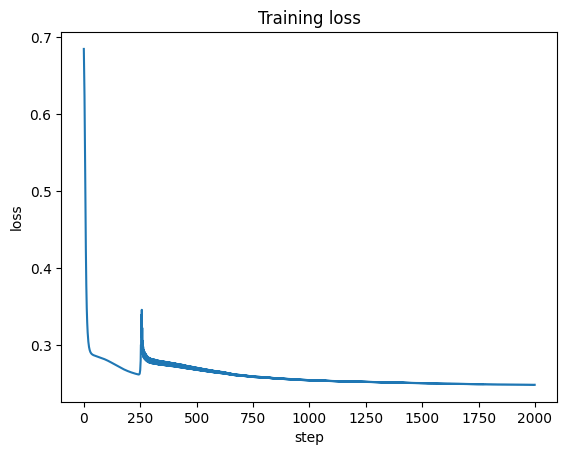

Neural net test acc: 0.89


In [10]:
lr = 1.0
losses = []

for step in range(2000):
    z1, a1, z2, p = forward(X_train, W1, b1, W2, b2)        # 1. Predict
    losses.append(bce(p, y_train))                          # 2. Measure
    dW1, db1, dW2, db2 = backward(X_train, y_train, z1, a1, p, W2)   # 3. Gradient
    W1 -= lr * dW1; b1 -= lr * db1                          # 4. Update
    W2 -= lr * dW2; b2 -= lr * db2
    if step % 500 == 0:
        print(f"step {step}: loss {losses[-1]:.4f}")

plt.plot(losses); plt.xlabel("step"); plt.ylabel("loss"); plt.title("Training loss")
plt.savefig("loss_curve.png"); plt.show()

p_test = forward(X_test, W1, b1, W2, b2)[3]
print("Neural net test acc:", ((p_test > 0.5) == y_test).mean())

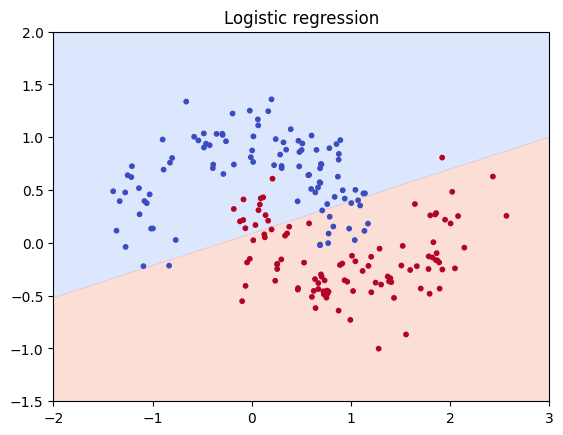

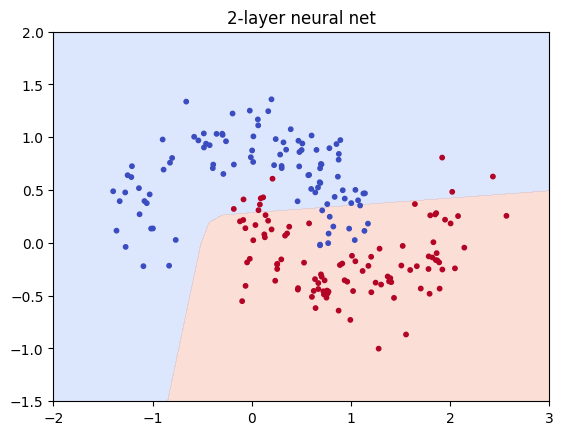

In [11]:
def plot_boundary(predict_fn, title, fname):
    xx, yy = np.meshgrid(np.linspace(-2, 3, 300), np.linspace(-1.5, 2, 300))
    grid = np.c_[xx.ravel(), yy.ravel()]
    zz = predict_fn(grid).reshape(xx.shape)
    plt.contourf(xx, yy, zz, levels=[0, 0.5, 1], cmap="coolwarm", alpha=0.3)
    plt.scatter(X_test[:, 0], X_test[:, 1], c=y_test.ravel(), cmap="coolwarm", s=10)
    plt.title(title); plt.savefig(fname); plt.show()

plot_boundary(lambda g: logreg.predict_proba(g)[:, 1], "Logistic regression", "boundary_logreg.png")
plot_boundary(lambda g: forward(g, W1, b1, W2, b2)[3], "2-layer neural net", "boundary_nn.png")